# Bressoux scenario setup

The **first** notebook to run: turns the raw smart-meter export
(`inputs/part-*.csv`) into everything `main.py`/MAS4TE need to simulate the
Bressoux LV/MV network, split in two:

- `inputs/` -- TRUE inputs, never overwritten by this notebook: the raw
  smart-meter data (`part-*.csv`), `coordinates.csv`, and the topology builder
  (`network.py`).
- `out/processed/` -- DERIVED data this notebook generates: `equipment.csv`,
  `metadata.csv`, `load_profiles.csv`, `mv_load_profiles.csv`, and the cached
  consumption bank / PVGIS irradiance reference.

Steps:

1. builds the Bressoux LV/MV network (`inputs/network.py`) and sanity-checks it,
2. visualizes it on a real map (Folium),
3. draws household consumption profiles from the real EAN smart meters (the
   monthly bank of real weeks) plus per-household metadata
   (`out/processed/load_profiles.csv`, `metadata.csv`),
4. generates the 4 MV load facility profiles (`out/processed/mv_load_profiles.csv`),
5. materializes the PVGIS irradiance reference needed for PV production
   (`out/processed/pvgis_irradiance_quarter_hourly.parquet`),
6. sanity-check plots of the profiles just generated,
7. places the scenario's equipment -- PV, domestic batteries, and the central
   battery -- as a single bus-level register (`out/processed/equipment.csv`),
8. visualizes the equipped network,
9. builds several **electrification scenarios** (Low/Medium/High heat-pump/
   water-heater/EV adoption, via `resflex`) as self-contained folders under
   `data/bressoux/scenarios/<name>/`, ready to feed `run_digital_twin` directly.

Run this notebook from **its own directory** (`data/bressoux/`) -- the
working directory Jupyter uses by default when this file is opened directly
(not the repository root: every path above, and `DATA_PATH = ""` in the next
cell, is relative to `data/bressoux/`).

In [2]:
import json
import os
import random

import numpy as np
import pandas as pd
import folium
import matplotlib.pyplot as plt

from digital_twin.utils import (load_site_network, STEPS_PER_DAY,
                                bank_path_for, irradiance_path_for)
from digital_twin.data_processing.profiles import (
    build_consumption_bank, build_irradiance_reference,
    generate_household_metadata, generate_load_profiles,
)
from digital_twin.data_processing.equipment import (
    generate_equipment_table, sync_household_equipment,
)

DATA_PATH = ""
INPUTS_DIR = "inputs"
OUT_DIR = "out/processed"
SEED = 42

# THE month of the scenario. It drives BOTH the real weeks the load profiles are
# drawn from AND the PV production month in main.py -- one setting, so charge and
# sun cannot end up on different seasons. Keep this equal to main.py's
# config['mois_simule'].
MOIS_SIMULE = 6

# Every asset's placement and physical size -- PV, domestic batteries, AND the
# central battery b0 -- is decided HERE, once, and baked into equipment.csv
# (see section 7). run_digital_twin/main.py never see bss_bus/bss_park_e_kwh/
# bss_park_p_kw: those are generation-time-only keys, consumed exclusively by
# generate_equipment_table's place_central_bss.
SCENARIO = {
    "data_path": DATA_PATH,
    "seed": SEED,
    "mois_simule": MOIS_SIMULE,
    "trafo_sn_mva": 0.22,
    "street_weights": {"Rue Ernest Malvoz": 3.0},
    "mv_pv_installations": {"Paradis du Bouhay": 12.0},  # PV sur les charges MT, {nom -> kWc}
    "bss_bus": "MALVOZ BRESSOUX",   # required for place_central_bss to place b0 at all
    "bss_park_e_kwh": 2600.0,
    "bss_park_p_kw": 595.0,
}


## 1. Build the network

In [3]:
network = load_site_network(SCENARIO)
net = network["net"]

print(f"Buses: {len(net.bus)} (expected 346)")
print(f"Lines: {len(net.line)} (expected 341)")
print(f"Transformers: {len(net.trafo)} (expected 4)")
print(f"Residential buses: {len(network['buses'])} (expected 333)")
print(f"MV nodes: {len(network['mv_nodes'])} (expected 9)")
if network["warnings"]:
    print("Warnings:")
    for w in network["warnings"]:
        print(" -", w)
else:
    print("No topology warnings.")

Buses: 346 (expected 346)
Lines: 341 (expected 341)
Transformers: 4 (expected 4)
Residential buses: 333 (expected 333)
MV nodes: 9 (expected 9)
No topology warnings.


## 2. Visualize the network on a real map

In [4]:
def _bus_latlon(bus_id):
    geo = json.loads(net.bus.loc[bus_id, "geo"])
    lon, lat = geo["coordinates"]
    return lat, lon

m = folium.Map(location=_bus_latlon(network["mv_nodes"]["SLACK"]), zoom_start=16, tiles="OpenStreetMap")

# Residential LV buses
for (street, num), bus_id in network["buses"].items():
    lat, lon = _bus_latlon(bus_id)
    folium.CircleMarker(
        location=(lat, lon), radius=3, color="#4C78A8", fill=True, fill_opacity=0.7,
        popup=f"{street} {num} (bus {bus_id})",
    ).add_to(m)

# MV substations (with transformer)
for name in ["TROULOUETTE", "CIMETIERE BRESSOUX", "MALVOZ BRESSOUX", "GROTTES"]:
    bus_id = network["mv_nodes"][name]
    lat, lon = _bus_latlon(bus_id)
    folium.Marker(
        location=(lat, lon), icon=folium.Icon(color="red", icon="bolt", prefix="fa"),
        popup=f"Substation: {name} (bus {bus_id})",
    ).add_to(m)

# MV load nodes (large consumers, no transformer)
for name in network["mv_load_names"]:
    bus_id = network["mv_nodes"][name]
    lat, lon = _bus_latlon(bus_id)
    folium.Marker(
        location=(lat, lon), icon=folium.Icon(color="green", icon="building", prefix="fa"),
        popup=f"MV load: {name} (bus {bus_id})",
    ).add_to(m)

# Slack (external grid connection)
lat, lon = _bus_latlon(network["mv_nodes"]["SLACK"])
folium.Marker(
    location=(lat, lon), icon=folium.Icon(color="black", icon="plug", prefix="fa"),
    popup="SLACK (external grid)",
).add_to(m)

m

## 3. Generate household metadata + consumption profiles

Both files come out of **one** act: the draw decides which real week -- hence
which street and which month -- backs each `profile_id`, so `metadata.csv` and
`load_profiles.csv` are written together by `generate_load_profiles`.

The profiles are drawn from the **monthly bank** of real EAN weeks, restricted
to `MOIS_SIMULE`. That is what keeps the loads on the same season as the PV:
`metadata['source_month']` records it, and the twin warns if a run simulates a
different month.

One household **per LV charge bus**: `metadata` carries the assignment in a
`bus_id` column, so the twin looks it up instead of drawing it again at run
time. That second draw used to leave 73% of the buses with a load bit-identical
to a neighbour's, peaking at the same instant.

Two more assumptions worth stating explicitly: the draw is **global across the
whole month's bank**, not restricted to a profile's own street -- on Bressoux,
street barely predicts consumption shape, and a global pool keeps reuse low
(~2.5x) and spread across the network instead of concentrated on one LV
feeder. When a real week is still drawn more than once, every *extra*
occurrence is time-shifted by a small, deterministic offset (the "jitter
ladder") so no two household profiles ever come out bit-identical.


In [5]:
# Bank of every complete real calendar week, tagged by month/season/street.
# Slow (it reads the full raw meter file), so it is skipped when already there --
# delete the parquet to force a rebuild.
bank_path = bank_path_for(DATA_PATH)
if os.path.exists(bank_path):
    bank = pd.read_parquet(bank_path)
    print(f"Banque deja materialisee : {bank_path} ({len(bank)} semaines)")
else:
    bank = build_consumption_bank(data_path=DATA_PATH)

print(f"\nSemaines disponibles pour le mois {MOIS_SIMULE} : "
      f"{int((bank['month'] == MOIS_SIMULE).sum())}")


Banque deja materialisee : out/processed/consumption_bank_real_weeks.parquet (1345 semaines)

Semaines disponibles pour le mois 6 : 133


In [6]:
# One household per LV charge bus, and metadata carries the assignment
# (bus_id) rather than leaving it to a draw inside the twin at run time.
metadata = generate_household_metadata(network)

households, metadata, load_warnings = generate_load_profiles(
    MOIS_SIMULE, metadata, config=SCENARIO, data_path=DATA_PATH)

for w in load_warnings:
    print(w)
print(f"\nhouseholds: {households.shape[0]} steps x {households.shape[1]} profiles -> "
      f"{os.path.join(OUT_DIR, 'load_profiles.csv')}")
print(f"metadata: {len(metadata)} rows -> {os.path.join(OUT_DIR, 'metadata.csv')}")
print(f"mois d'origine des profils : {sorted(metadata['source_month'].dropna().unique())}")
print(f"affectation menage -> bus  : {metadata['bus_id'].nunique()} bus BT, 1:1")
metadata.head()


[LOAD/draw] 333 profile(s) drawn from 133 real week(s) of month 6: 133/133 distinct week(s) used, max reuse 3x, 200 profile(s) jittered.

households: 672 steps x 333 profiles -> out/processed/load_profiles.csv
metadata: 333 rows -> out/processed/metadata.csv
mois d'origine des profils : [np.int64(6)]
affectation menage -> bus  : 333 bus BT, 1:1


,profile_id,bus_id,constellation,building_type,heat_pump,electric_water_heating,electric_vehicle_type,n_persons,pv_system_size_kwp,battery_size_kwh,source_street,source_month,source_week_start,source_ean_index
0,0,9,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Avenue Joseph Merlot,6,2025-06-16T00:00:00+00:00,26
1,1,10,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Avenue Joseph Merlot,6,2025-06-23T00:00:00+00:00,28
2,2,11,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Avenue Joseph Merlot,6,2025-06-02T00:00:00+00:00,25
3,3,12,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Avenue Joseph Merlot,6,2025-06-02T00:00:00+00:00,5
4,4,13,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Rue Ernest Malvoz,6,2025-06-30T00:00:00+00:00,30


All scenario columns (`heat_pump`, `electric_water_heating`, `pv_system_size_kwp`,
`battery_size_kwh`, `n_persons`, `constellation`, `building_type`,
`electric_vehicle_type`) default to `False`/`0.0`/unknown — no household is
equipped with anything yet. PV/battery placement comes in section 7 below;
heat pump/water heater/EV adoption comes in section 9.

## 4. Generate the MV load facility profiles

The 4 MV load facilities (rest home, school, sports hall, horticultural
centre) are large consumers connected directly at MV, each with its own
deterministic day/time profile (not drawn from the residential EAN data).
Ported from the historical `profil_conso.ipynb`: pure electricity consumption
only (lighting, IT, ventilation, pumps, lifts, kitchen) -- space/water heating
is excluded (a different energy vector).

In [7]:
random.seed(SEED)

N_PER_WEEK = 7 * 96
_days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
time_index = [
    f"{_days[step // 96]} {(step % 96) * 15 // 60:02d}:{(step % 96) * 15 % 60:02d}"
    for step in range(N_PER_WEEK)
]


def get_mr_power(day_of_week, time_val):
    """Rest home ('Paradis du Bouhay') -- lighting, kitchen, lifts, cold rooms
    and auxiliaries. Space/water heating excluded (separate energy vector)."""
    power = 28.0
    is_weekend = day_of_week >= 5
    if 6.5 <= time_val < 11.5:
        power = 42.0
    elif 11.5 <= time_val < 14.0:
        power = 58.0
    elif 14.0 <= time_val < 17.5:
        power = 38.0
    elif 17.5 <= time_val < 20.0:
        power = 48.0
    elif 20.0 <= time_val < 22.5:
        power = 34.0
    if is_weekend:
        power *= 0.92
    return power * random.uniform(0.96, 1.04)


def get_ecole_power(day_of_week, time_val):
    """School ('Groupe Scolaire') -- lighting, IT, ambient ventilation. Heating
    excluded."""
    is_weekend = day_of_week >= 5
    is_wednesday = day_of_week == 2
    if is_weekend:
        return 0.8 * random.uniform(0.95, 1.05)
    if 7.5 <= time_val < 8.5:
        return 8.0 * random.uniform(0.95, 1.05)
    elif 8.5 <= time_val < 12.0:
        return 12.0 * random.uniform(0.95, 1.05)
    elif 12.0 <= time_val < 13.5:
        return 9.0 * random.uniform(0.95, 1.05)
    elif 13.5 <= time_val < 16.0:
        return (1.5 if is_wednesday else 11.0) * random.uniform(0.95, 1.05)
    elif 16.0 <= time_val < 18.0:
        return 4.0 * random.uniform(0.95, 1.05)
    else:
        return 1.2 * random.uniform(0.95, 1.05)


def get_hall_sport_power(day_of_week, time_val):
    """Sports hall ('Omnisport BX') -- track lighting and ventilation. Shower
    water heating excluded."""
    is_weekend = day_of_week >= 5
    if not is_weekend:
        if 8.0 <= time_val < 16.0:
            return 5.0 * random.uniform(0.92, 1.08)
        elif 16.0 <= time_val < 17.5:
            return 8.0 * random.uniform(0.95, 1.05)
        elif 17.5 <= time_val < 22.5:
            return 22.0 * random.uniform(0.95, 1.05)
        else:
            return 1.5 * random.uniform(0.95, 1.05)
    else:
        if 8.5 <= time_val < 21.5:
            return 18.0 * random.uniform(0.93, 1.07)
        else:
            return 1.8 * random.uniform(0.95, 1.05)


def get_horticole_power(day_of_week, time_val):
    """Horticultural centre ('Plantations') -- grow lighting, irrigation pumps,
    greenhouse vents. Greenhouse heating excluded."""
    is_weekend = day_of_week >= 5
    base_tech = 2.5 if is_weekend else 3.5
    if 7.5 <= time_val < 16.5:
        activity = 8.0 if not is_weekend else 1.5
        return (base_tech + activity) * random.uniform(0.95, 1.05)
    else:
        return base_tech * random.uniform(0.95, 1.05)


mv_load_profiles_kw = {name: [] for name in network["mv_load_names"]}
for step in range(N_PER_WEEK):
    dow = step // 96
    time_val = (step % 96) * 15 / 60.0
    mv_load_profiles_kw["Paradis du Bouhay"].append(get_mr_power(dow, time_val))
    mv_load_profiles_kw["Groupe Scolaire"].append(get_ecole_power(dow, time_val))
    mv_load_profiles_kw["Omnisport BX"].append(get_hall_sport_power(dow, time_val))
    mv_load_profiles_kw["Plantations"].append(get_horticole_power(dow, time_val))

mv_load_profiles = pd.DataFrame(mv_load_profiles_kw, index=time_index)  # kW, like load_profiles.csv
mv_load_profiles.index.name = "week_step"
mv_load_profiles.to_csv(os.path.join(OUT_DIR, "mv_load_profiles.csv"))
print(f"mv_load_profiles: {mv_load_profiles.shape} -> "
      f"{os.path.join(OUT_DIR, 'mv_load_profiles.csv')}")
mv_load_profiles.describe()

mv_load_profiles: (672, 4) -> out/processed/mv_load_profiles.csv


,Paradis du Bouhay,Plantations,Omnisport BX,Groupe Scolaire
count,672.000000,672.000000,672.000000,672.000000
mean,37.324483,5.526536,8.282225,3.517770
std,9.468422,3.651888,8.014819,4.149857
min,24.822933,2.377119,1.425061,0.760278
25%,28.344665,3.392568,1.555589,0.829692
50%,36.943580,3.575280,4.936683,1.204260
75%,42.705483,11.013337,17.562163,4.055973
max,60.176143,12.070511,23.058529,12.588739


Should be validated.

## 5. Generate the PV irradiance reference

Needed by `process_data` to build `pv_profiles` from the equipment table's
PV-equipped rows (see `digital_twin.data_processing.pv.build_pv_production`).
Fetched once from PVGIS and cached -- skipped if already materialized.

In [8]:
irradiance_path = irradiance_path_for(DATA_PATH)

if os.path.exists(irradiance_path):
    print(f"Already materialized: {irradiance_path}")
else:
    # SCENARIO, pas seulement le chemin : la latitude/longitude est deduite du
    # centroide des bus BT du reseau (utils.site_centroid), donc la fonction a
    # besoin de savoir quel site charger.
    build_irradiance_reference(SCENARIO)


Already materialized: out/processed/pvgis_irradiance_quarter_hourly.parquet


## 6. Sanity check plots

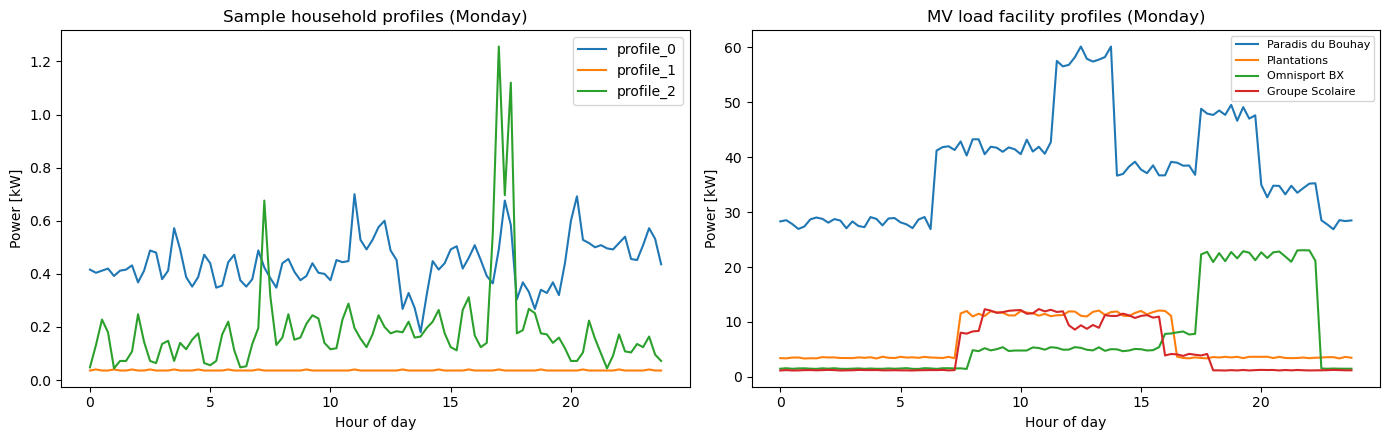

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

t = np.arange(STEPS_PER_DAY) * 0.25
for i in range(3):
    day_vals = households[f"profile_{i}"].to_numpy()[:STEPS_PER_DAY]
    axes[0].plot(t, day_vals, label=f"profile_{i}")
axes[0].set_title("Sample household profiles (Monday)")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Power [kW]")
axes[0].legend()

for name in network["mv_load_names"]:
    day_vals = mv_load_profiles[name].to_numpy()[:STEPS_PER_DAY]
    axes[1].plot(t, day_vals, label=name)
axes[1].set_title("MV load facility profiles (Monday)")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Power [kW]")
axes[1].legend(fontsize=8)

fig.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "sample_profiles.png"), dpi=300)
plt.show()

## 7. Place the equipment (PV + domestic batteries + the central battery)

`equipment.csv` is the **one** register the scenario hangs on: one row per
equipable bus (333 LV + 4 MV load facilities + the other MV nodes), carrying
the PV sizes and the battery ids/capacities -- **every** battery, the central
one (`b0`) included. It replaces the separate files/config keys that used to
carry this (`pv_installations.csv`, and `bss_bus`/`bss_park_e_kwh`/
`bss_park_p_kw` as runtime config).

All three layers switch on from the table's **content**: a bus with
`pv_system_size_kwp > 0` gets PV, a bus with `battery_size_kwh > 0` gets a
battery. `b0` (the central battery) is placed on the ONE MV node named by
`SCENARIO['bss_bus']`, `b1..bn` (domestic) on LV buses -- generated once, here,
never passed to `run_digital_twin` as a config scalar.


In [10]:
equipment = generate_equipment_table(SCENARIO)

# metadata porte pv_system_size_kwp / battery_size_kwh (schema MAS4TE), mais
# c'est la table AU NIVEAU BUS qui fait foi. On projette, sinon ces colonnes
# restent a 0.0 et lisent "aucune batterie" pour des bus qui en portent une.
metadata = sync_household_equipment(metadata, equipment)
metadata.to_csv(os.path.join(OUT_DIR, "metadata.csv"), index=False)

has_battery = equipment["battery_size_kwh"].fillna(0.0) > 0
is_central = equipment["battery_id"] == "b0"
n_pv = int((equipment["pv_system_size_kwp"].fillna(0.0) > 0).sum())
n_bat = int((has_battery & ~is_central).sum())   # domestic only -- b0 excluded
central_row = equipment[has_battery & is_central]

print(f"equipment.csv : {len(equipment)} bus equipables -> "
      f"{os.path.join(OUT_DIR, 'equipment.csv')}")
print(f"  PV        : {n_pv} installations, "
      f"{equipment['pv_system_size_kwp'].fillna(0.0).sum():.1f} kWc au total")
print(f"  batteries : {n_bat} domestiques (b1..b{n_bat}), "
      f"{equipment.loc[has_battery & ~is_central, 'battery_size_kwh'].sum():.0f} kWh")
if len(central_row):
    r = central_row.iloc[0]
    print(f"  + b0 centrale : {r['battery_size_kwh']:.0f} kWh / "
          f"{r['battery_p_max_kw']:.0f} kW sur le noeud MT {r['name']!r} (bus {int(r['bus_id'])})")
else:
    print("  + pas de batterie centrale (SCENARIO['bss_bus'] absent)")
print(f"metadata resynchronisee : "
      f"{int((metadata['pv_system_size_kwp'].fillna(0) > 0).sum())} menages avec PV, "
      f"{int((metadata['battery_size_kwh'].fillna(0) > 0).sum())} avec batterie")

equipment[has_battery & ~is_central][
    ["bus_id", "bus_type", "street", "num", "pv_system_size_kwp", "battery_id",
     "battery_size_kwh", "battery_p_max_kw"]
].head()


equipment.csv : 342 bus equipables -> out/processed/equipment.csv
  PV        : 31 installations, 102.0 kWc au total
  batteries : 20 domestiques (b1..b20), 200 kWh
  + b0 centrale : 2600 kWh / 595 kW sur le noeud MT 'MALVOZ BRESSOUX' (bus 3)
metadata resynchronisee : 30 menages avec PV, 20 avec batterie


,bus_id,bus_type,street,num,pv_system_size_kwp,battery_id,battery_size_kwh,battery_p_max_kw
13,13,lv_residential,Rue Ernest Malvoz,93.0,3.0,b1,10.0,0.0
15,15,lv_residential,Rue Ernest Malvoz,89.0,3.0,b2,10.0,0.0
19,19,lv_residential,Rue Ernest Malvoz,77.0,3.0,b3,10.0,0.0
37,37,lv_residential,Rue Ernest Malvoz,29.0,3.0,b4,10.0,0.0
39,39,lv_residential,Rue Ernest Malvoz,25.0,3.0,b5,10.0,0.0


## 8. The network once equipped

Same map as section 2, with the scenario's equipment on top: PV installations in
orange, domestic batteries in green, and the central battery `b0` on its MV node.
Comparing the two maps shows what the scenario actually added -- and where the
clusters landed, which is what drives local overvoltage.


In [11]:
has_battery = equipment["battery_size_kwh"].fillna(0.0) > 0
is_central = equipment["battery_id"] == "b0"
equipped_pv = equipment[equipment["pv_system_size_kwp"].fillna(0.0) > 0]
equipped_bat = equipment[has_battery & ~is_central]
central_row = equipment[has_battery & is_central]
pv_buses = set(equipped_pv["bus_id"].astype(int))
bat_by_bus = {int(r.bus_id): r for r in equipped_bat.itertuples()}

m2 = folium.Map(location=_bus_latlon(network["mv_nodes"]["SLACK"]),
                zoom_start=16, tiles="OpenStreetMap")

# Every LV bus, greyed out unless it carries something
for (street, num), bus_id in network["buses"].items():
    lat, lon = _bus_latlon(bus_id)
    has_pv, bat = bus_id in pv_buses, bat_by_bus.get(bus_id)
    if bat is not None:
        color, radius, label = "#2E8B57", 6, f"{bat.battery_id} -- {bat.battery_size_kwh:.0f} kWh"
    elif has_pv:
        color, radius, label = "#E8730C", 5, "PV"
    else:
        color, radius, label = "#4C78A8", 2, "aucun equipement"
    if has_pv and bat is not None:
        label = f"PV + {label}"
    folium.CircleMarker(
        location=(lat, lon), radius=radius, color=color, fill=True, fill_opacity=0.85,
        popup=f"{street} {num} (bus {bus_id}) -- {label}",
    ).add_to(m2)

# MV load facilities: PV-capable too (the rest home carries a large array)
for name in network["mv_load_names"]:
    bus_id = network["mv_nodes"][name]
    lat, lon = _bus_latlon(bus_id)
    row = equipment[equipment["bus_id"] == bus_id]
    kwp = float(row["pv_system_size_kwp"].fillna(0.0).iloc[0]) if len(row) else 0.0
    folium.Marker(
        location=(lat, lon),
        icon=folium.Icon(color="orange" if kwp > 0 else "green", icon="building", prefix="fa"),
        popup=f"MV load: {name} (bus {bus_id})" + (f" -- PV {kwp:.0f} kWc" if kwp else ""),
    ).add_to(m2)

# Central battery b0 -- read straight off equipment (its own row), not off
# SCENARIO/network: this is what makes the map show what was actually placed,
# not what was configured.
legend_central = ""
if len(central_row):
    r = central_row.iloc[0]
    b0_bus, b0_name = int(r["bus_id"]), r["name"]
    lat, lon = _bus_latlon(b0_bus)
    folium.Marker(
        location=(lat, lon), icon=folium.Icon(color="darkgreen", icon="car-battery", prefix="fa"),
        popup=(f"b0 -- batterie centrale (bus {b0_bus}, {b0_name})<br>"
               f"{r['battery_size_kwh']:.0f} kWh / {r['battery_p_max_kw']:.0f} kW"),
    ).add_to(m2)
    # folium.Circle(location=(lat, lon), radius=60, color="#2E8B57", fill=False, weight=2).add_to(m2)
    legend_central = f'<span style="color:#2E8B57">&#9711;</span> b0 centrale sur {b0_name}'

legend = (
    '<div style="position:fixed;bottom:24px;left:24px;z-index:9999;background:white;'
    'padding:10px 14px;border:1px solid #999;border-radius:4px;font-size:13px">'
    f'<b>Equipement du scenario</b><br>'
    f'<span style="color:#E8730C">&#9679;</span> PV ({n_pv})<br>'
    f'<span style="color:#2E8B57">&#9679;</span> batterie domestique ({n_bat})<br>'
    f'<span style="color:#4C78A8">&#9679;</span> bus BT sans equipement<br>'
    f'{legend_central}'
    '</div>'
)
m2.get_root().html.add_child(folium.Element(legend))
m2


## 9. Household electrification scenarios (resflex)

`metadata.csv` still carries `heat_pump`, `electric_water_heating` and
`electric_vehicle_type` at their defaults (`False`/`False`/unknown) — the
equipment table above only placed PV and domestic batteries, nothing decides
yet which households get a heat pump, a water boiler or an EV.

We use `resflex` (a StROBe-based residential load generator, a local dev
dependency of this notebook's environment only — see
`data/bressoux/resflex_scenarios.py`) to build **several self-contained
scenario folders** under `data/bressoux/scenarios/<name>/`, each a full
`data_path` that `process_data`/`run_digital_twin` can load unmodified:

- resflex decides, per household and per scenario, which houses get a heat
  pump / water boiler / EV — driven by per-household equipment
  *probabilities* (`P_HP`, `P_WB`, `P_EV`, resflex's own mechanism, not
  counts).
- Their simulated power draw (HP/WB/EV only — resflex's own StROBe baseload
  is discarded) is **added on top of** the household's existing
  real-smart-meter consumption profile: a pure additive "electrification
  overlay", no flexibility/optimization involved.
- The PV/battery side of each scenario reuses `digital_twin.data_processing
  .equipment` directly (`extend_pv` off the base `equipment.csv`, same
  bus-level register as section 7) — resflex's own PV/BSS sampling stays
  unused, exactly as before.

`resflex` itself is **not** a dependency of the installable `digital_twin`
package — MAS4TE agents only ever call `run_digital_twin` with the resulting
`metadata`/`load_profiles`/`equipment` files, never resflex.

In [12]:
import importlib.util

# resflex_scenarios.py lives next to this notebook, not under digital_twin/
# (see the markdown above) -- loaded the same way load_site_network loads a
# site's inputs/network.py, so it works regardless of sys.path.
_spec = importlib.util.spec_from_file_location(
    "resflex_scenarios", os.path.join(DATA_PATH, "resflex_scenarios.py"))
resflex_scenarios = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(resflex_scenarios)

# Preset electrification levels: per-household equipment probabilities
# (resflex's P_HP/P_WB/P_EV) paired with a PV extension of the base
# equipment.csv (built in section 7). "Low" intentionally reproduces today's
# scenario exactly (no assets added, equipment table reused as-is) -- a
# control scenario.
ELECTRIFICATION_SCENARIOS = {
    "low": {
        "flex_probabilities": {"P_HP": 0.0, "P_WB": 0.0, "P_EV": 0.0},
        "pv_spec": {"mode": "reuse"},
    },
    "medium": {
        "flex_probabilities": {"P_HP": 0.3, "P_WB": 0.5, "P_EV": 0.15},
        "pv_spec": {"mode": "extend", "n_additional": 20},   # 30 -> 50 residential installations
    },
    "high": {
        "flex_probabilities": {"P_HP": 0.6, "P_WB": 1.0, "P_EV": 0.4},
        "pv_spec": {"mode": "extend", "n_additional": 50},   # 30 -> 80 residential installations
    },
}

# State the assumption up front, as a table, rather than leaving the reader to
# infer it from the dict literal above.
scenario_def = pd.DataFrame({
    name: {
        "P(heat pump)": spec["flex_probabilities"]["P_HP"],
        "P(water heater)": spec["flex_probabilities"]["P_WB"],
        "P(EV)": spec["flex_probabilities"]["P_EV"],
        "PV": ("reused as-is (30 installations)" if spec["pv_spec"]["mode"] == "reuse"
              else f"+{spec['pv_spec']['n_additional']} installations "
                   f"({30 + spec['pv_spec']['n_additional']} total)"),
    }
    for name, spec in ELECTRIFICATION_SCENARIOS.items()
}).T
scenario_def.index.name = "scenario"
scenario_def

,P(heat pump),P(water heater),P(EV),PV
scenario,,,,
low,0.0,0.0,0.0,reused as-is (30 installations)
medium,0.3,0.5,0.15,+20 installations (50 total)
high,0.6,1.0,0.4,+50 installations (80 total)


Simulation of the households profiles based on resflex package. This takes around 1sec/week/household to generate so ~14 minutes to fully run for 3 full scenarios.

In [13]:
scenario_paths = {}
for name, spec in ELECTRIFICATION_SCENARIOS.items():
    print(f"Building scenario '{name}' ({spec['flex_probabilities']}, pv={spec['pv_spec']}) ...")
    scenario_paths[name] = resflex_scenarios.build_scenario(
        name, spec["flex_probabilities"], spec["pv_spec"], seed=SEED,
        base_data_path=DATA_PATH, base_config=SCENARIO)
    print(f"  -> {scenario_paths[name]}")

Building scenario 'low' ({'P_HP': 0.0, 'P_WB': 0.0, 'P_EV': 0.0}, pv={'mode': 'reuse'}) ...
Simulating household_1 (1/333)
Simulation is done. Execution time: 0.54 s.
Simulating household_2 (2/333)
Simulation is done. Execution time: 0.87 s.
Simulating household_3 (3/333)
Simulation is done. Execution time: 0.39 s.
Simulating household_4 (4/333)
Simulation is done. Execution time: 0.51 s.
Simulating household_5 (5/333)
Simulation is done. Execution time: 0.34 s.
Simulating household_6 (6/333)
Simulation is done. Execution time: 0.49 s.
Simulating household_7 (7/333)
Simulation is done. Execution time: 0.75 s.
Simulating household_8 (8/333)
Simulation is done. Execution time: 0.34 s.
Simulating household_9 (9/333)
Simulation is done. Execution time: 0.58 s.
Simulating household_10 (10/333)
Simulation is done. Execution time: 0.55 s.
Simulating household_11 (11/333)
Simulation is done. Execution time: 0.68 s.
Simulating household_12 (12/333)
Simulation is done. Execution time: 0.54 s.
Si

,heat_pump,water_heater,EV,PV,domestic_battery,n_households
scenario,,,,,,
low,0,0,0,31,20,333
medium,114,165,42,51,20,333
high,206,333,121,81,20,333


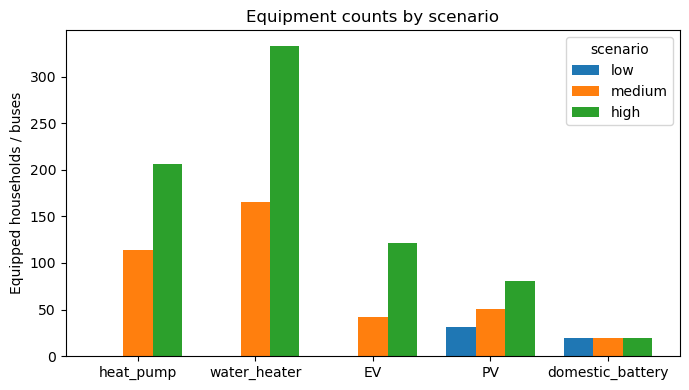

In [14]:
equip_counts = {}
for name, path in scenario_paths.items():
    scenario_metadata = pd.read_csv(os.path.join(path, "out", "processed", "metadata.csv"))
    scenario_equipment = pd.read_csv(os.path.join(path, "out", "processed", "equipment.csv"))
    has_bat = scenario_equipment["battery_size_kwh"].fillna(0.0) > 0
    is_central = scenario_equipment["battery_id"] == "b0"
    equip_counts[name] = {
        "heat_pump": int(scenario_metadata["heat_pump"].astype(bool).sum()),
        "water_heater": int(scenario_metadata["electric_water_heating"].astype(bool).sum()),
        "EV": int(scenario_metadata["electric_vehicle_type"].notna().sum()),
        "PV": int((scenario_equipment["pv_system_size_kwp"].fillna(0.0) > 0).sum()),
        "domestic_battery": int((has_bat & ~is_central).sum()),   # b0 excluded
        "n_households": len(scenario_metadata),
    }
equip_counts = pd.DataFrame(equip_counts).T
equip_counts.index.name = "scenario"
display(equip_counts)

fig, ax = plt.subplots(figsize=(7, 4))
assets = ["heat_pump", "water_heater", "EV", "PV", "domestic_battery"]
x = np.arange(len(assets))
width = 0.25
for i, name in enumerate(ELECTRIFICATION_SCENARIOS):
    ax.bar(x + (i - 1) * width, equip_counts.loc[name, assets], width, label=name)
ax.set_xticks(x)
ax.set_xticklabels(assets)
ax.set_ylabel("Equipped households / buses")
ax.set_title("Equipment counts by scenario")
ax.legend(title="scenario")
fig.tight_layout()
plt.show()

What the "additive overlay" claim actually looks like: one household's real
smart-meter base load against the same profile once resflex's HP/WB/EV draw is
added on top (the "high" scenario, picked because it has the most equipped
households to choose from).

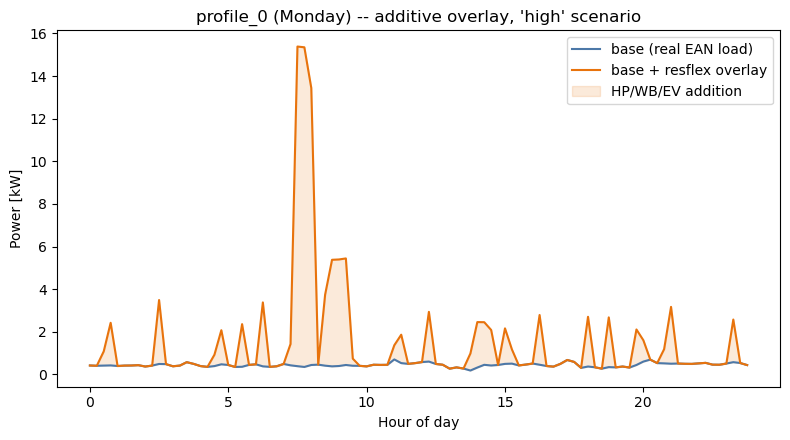

profile_0: heat_pump=True, water_heater=True, EV=True
peak base: 2.31 kW  |  peak with overlay: 17.87 kW


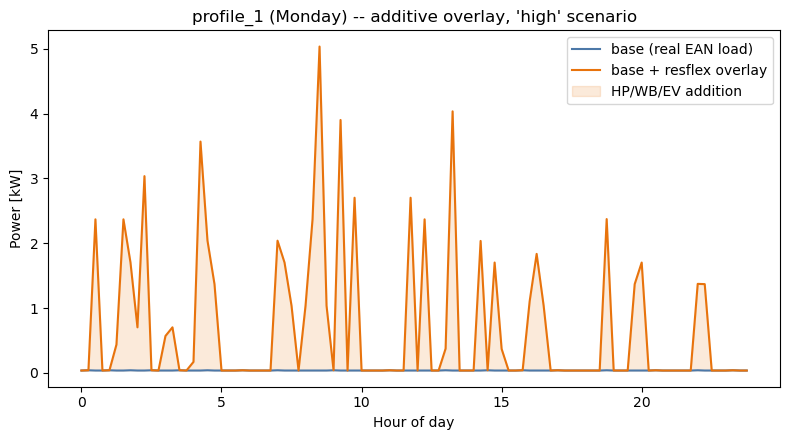

profile_1: heat_pump=True, water_heater=True, EV=True
peak base: 0.04 kW  |  peak with overlay: 13.04 kW


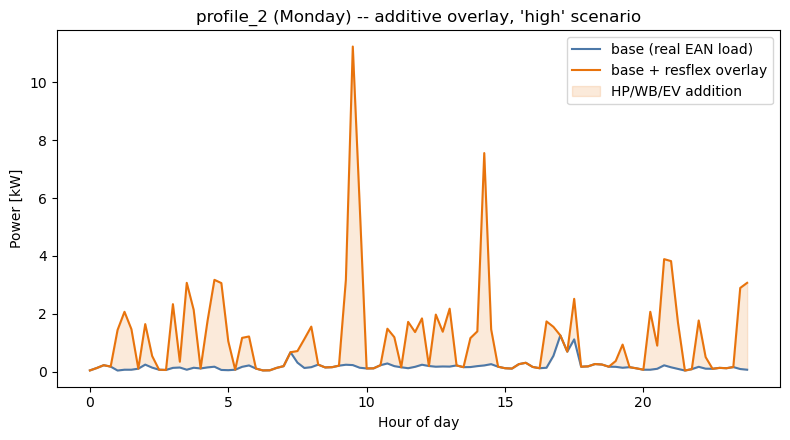

profile_2: heat_pump=False, water_heater=True, EV=True
peak base: 1.26 kW  |  peak with overlay: 12.26 kW


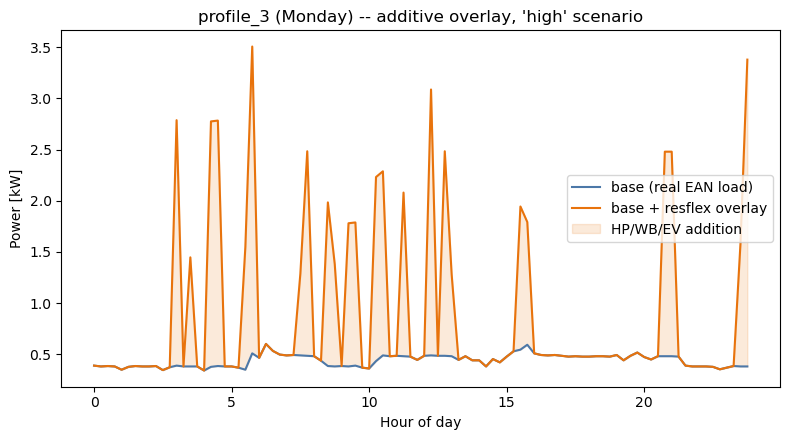

profile_3: heat_pump=True, water_heater=True, EV=False
peak base: 1.20 kW  |  peak with overlay: 3.84 kW


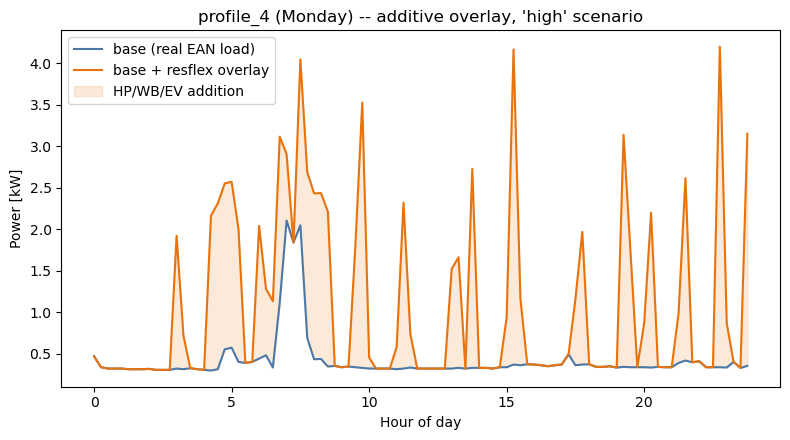

profile_4: heat_pump=True, water_heater=True, EV=True
peak base: 2.56 kW  |  peak with overlay: 11.34 kW


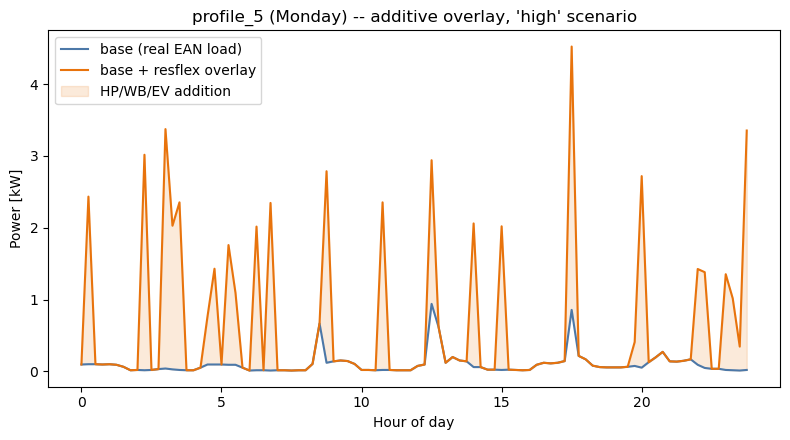

profile_5: heat_pump=False, water_heater=True, EV=False
peak base: 1.67 kW  |  peak with overlay: 5.94 kW


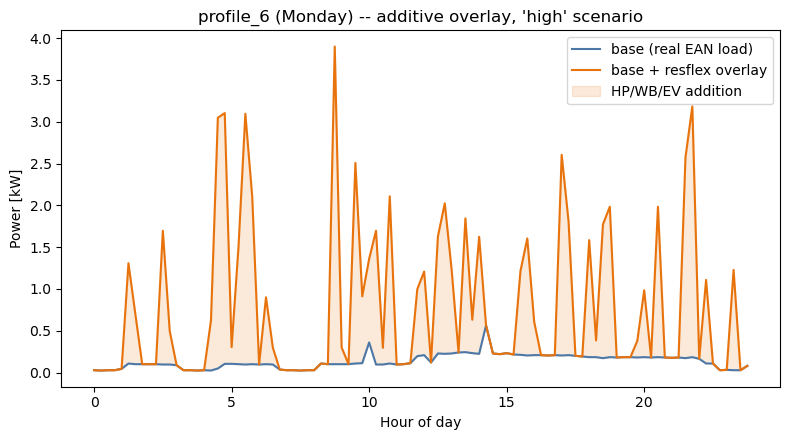

profile_6: heat_pump=True, water_heater=True, EV=False
peak base: 2.44 kW  |  peak with overlay: 4.90 kW


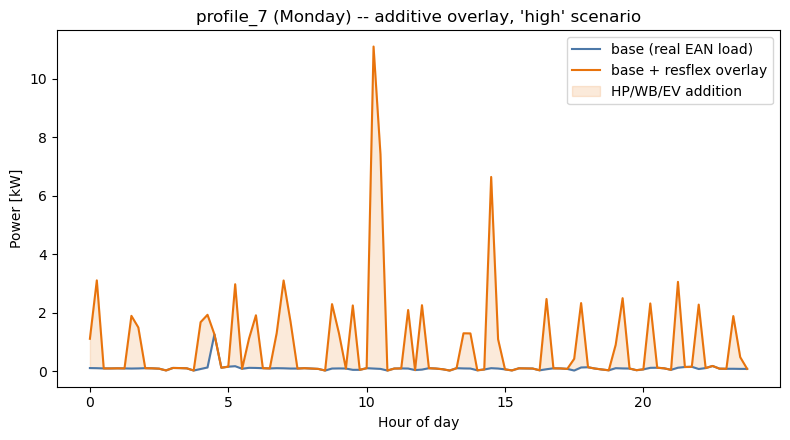

profile_7: heat_pump=False, water_heater=True, EV=True
peak base: 1.93 kW  |  peak with overlay: 12.71 kW


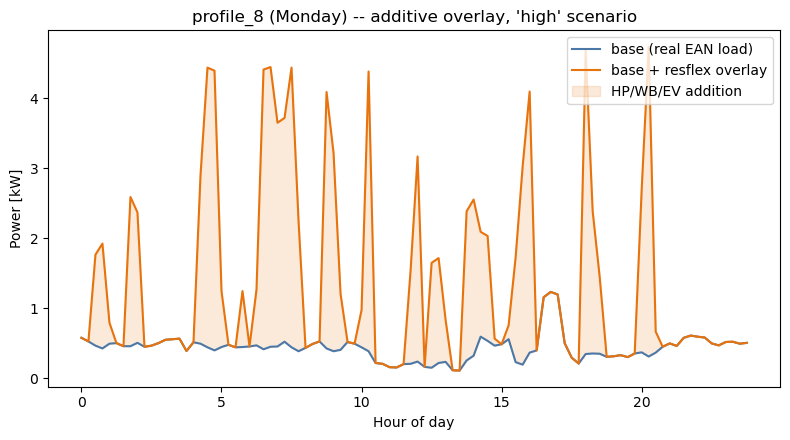

profile_8: heat_pump=True, water_heater=True, EV=False
peak base: 2.46 kW  |  peak with overlay: 5.68 kW


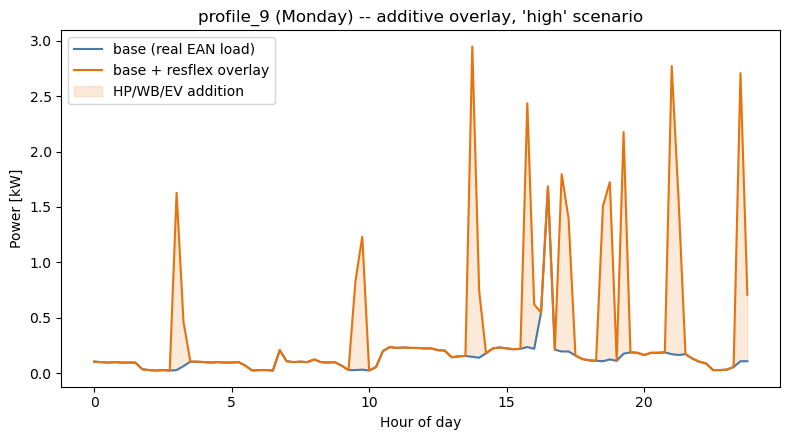

profile_9: heat_pump=False, water_heater=True, EV=False
peak base: 1.68 kW  |  peak with overlay: 3.29 kW


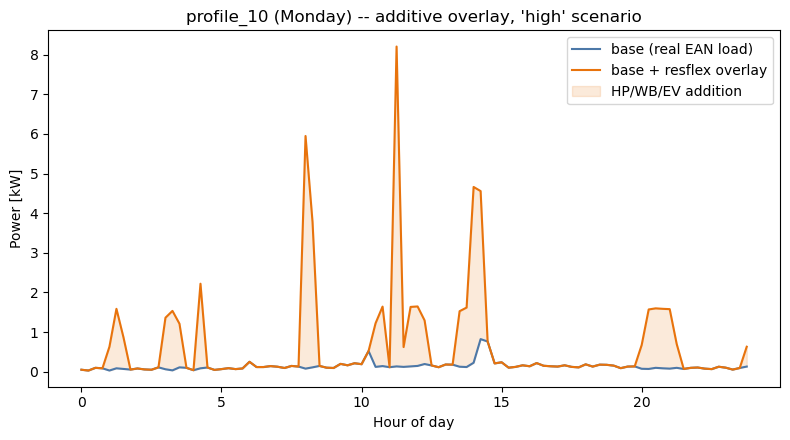

profile_10: heat_pump=True, water_heater=True, EV=True
peak base: 1.44 kW  |  peak with overlay: 10.35 kW


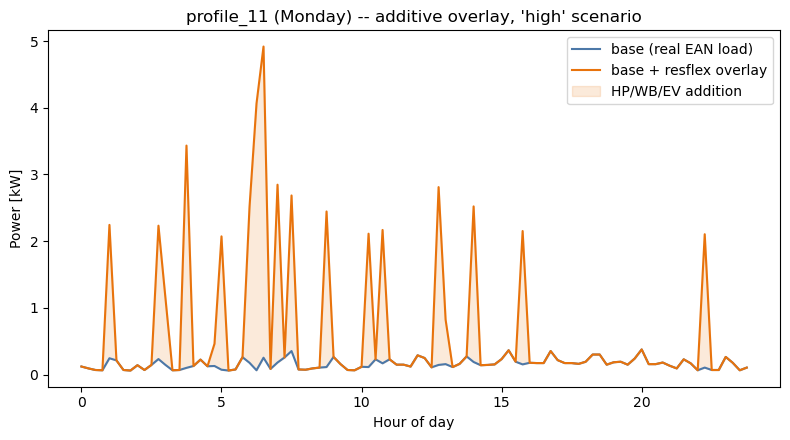

profile_11: heat_pump=False, water_heater=True, EV=False
peak base: 1.34 kW  |  peak with overlay: 5.31 kW


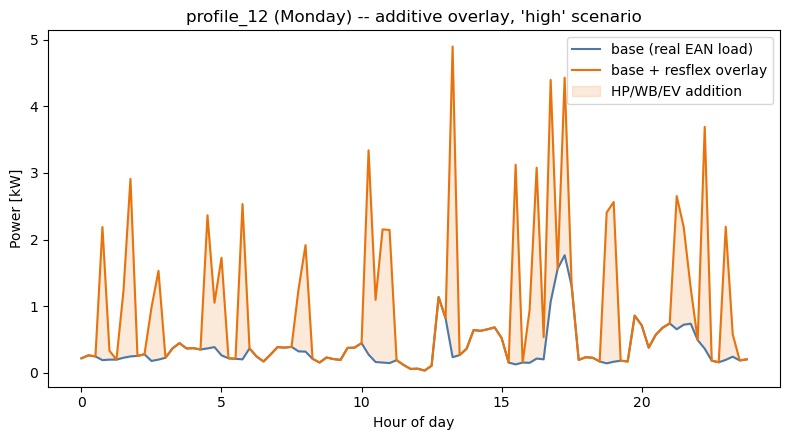

profile_12: heat_pump=True, water_heater=True, EV=False
peak base: 2.95 kW  |  peak with overlay: 6.77 kW


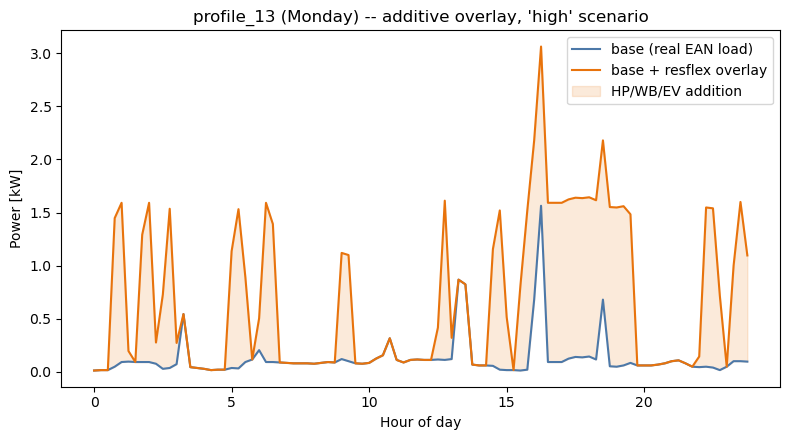

profile_13: heat_pump=False, water_heater=True, EV=True
peak base: 2.21 kW  |  peak with overlay: 12.65 kW


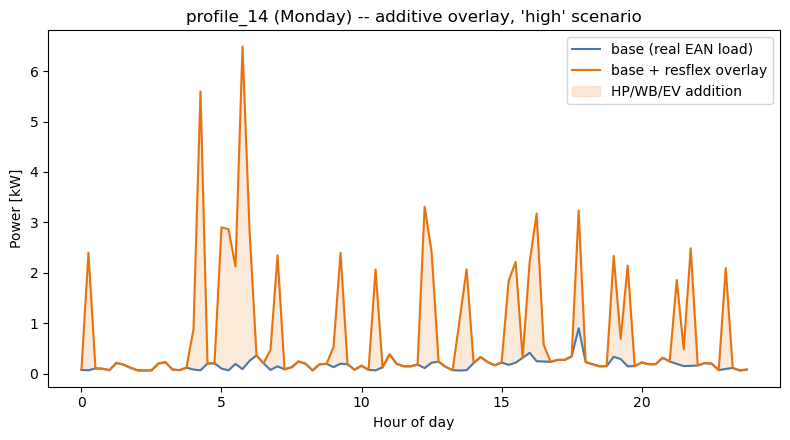

profile_14: heat_pump=True, water_heater=True, EV=False
peak base: 0.90 kW  |  peak with overlay: 6.49 kW


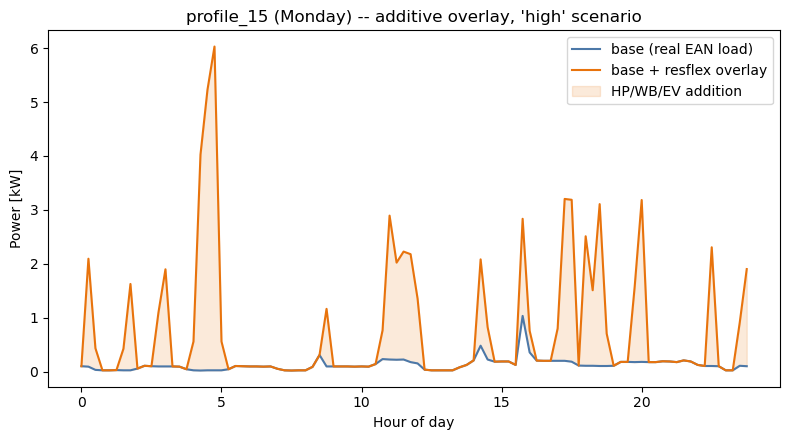

profile_15: heat_pump=True, water_heater=True, EV=False
peak base: 1.64 kW  |  peak with overlay: 6.30 kW


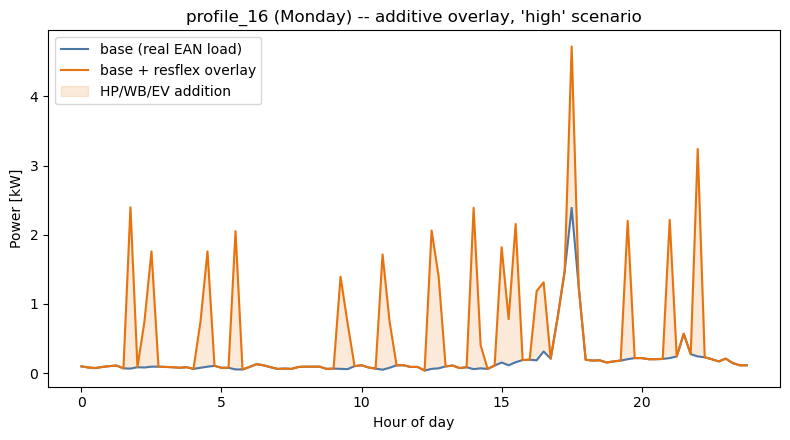

profile_16: heat_pump=False, water_heater=True, EV=False
peak base: 2.53 kW  |  peak with overlay: 5.70 kW


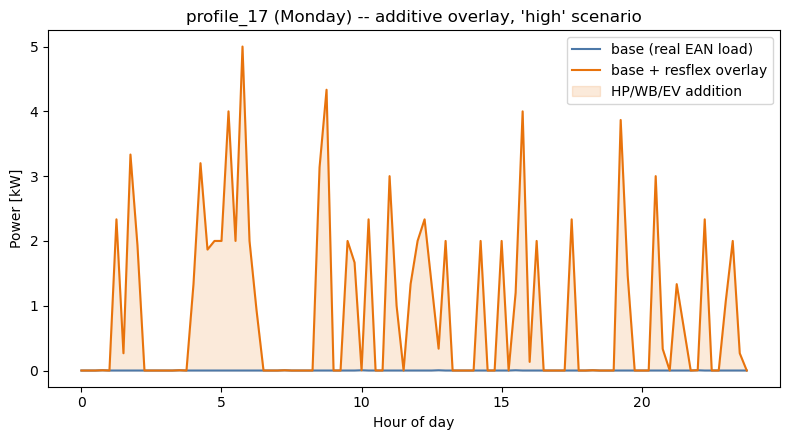

profile_17: heat_pump=True, water_heater=True, EV=False
peak base: 0.00 kW  |  peak with overlay: 5.67 kW


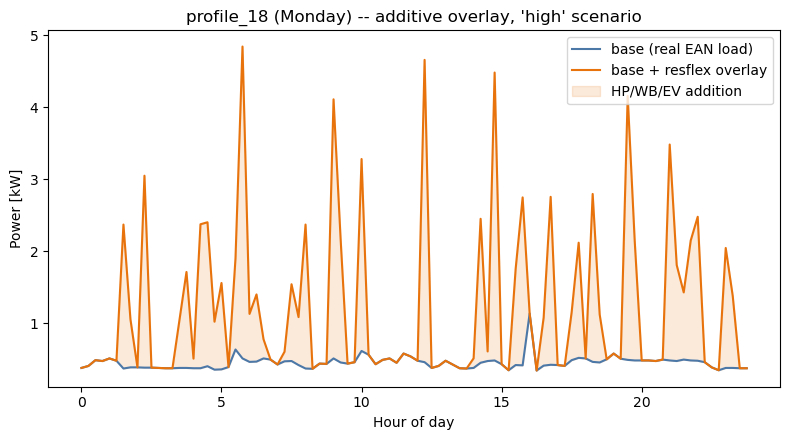

profile_18: heat_pump=True, water_heater=True, EV=False
peak base: 1.14 kW  |  peak with overlay: 6.48 kW


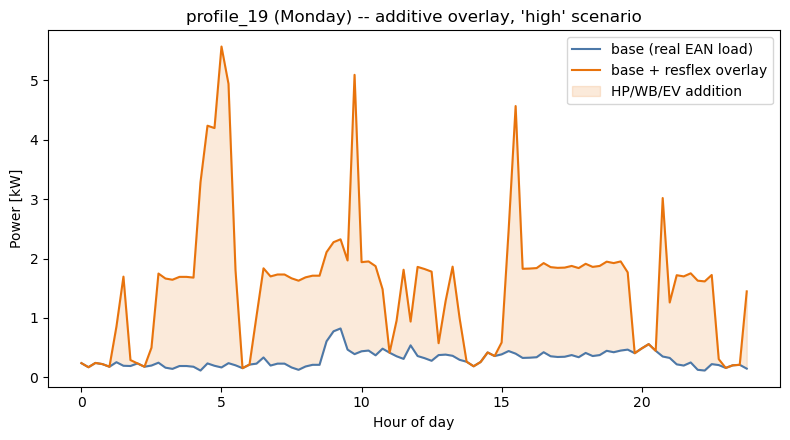

profile_19: heat_pump=True, water_heater=True, EV=False
peak base: 3.06 kW  |  peak with overlay: 5.66 kW


In [20]:
base_households = pd.read_csv(os.path.join(OUT_DIR, "load_profiles.csv"), index_col=0)

high_metadata = pd.read_csv(os.path.join(scenario_paths["high"], "out", "processed", "metadata.csv"))
high_households = pd.read_csv(
    os.path.join(scenario_paths["high"], "out", "processed", "load_profiles.csv"), index_col=0)

fully_equipped = high_metadata[
    high_metadata["heat_pump"].astype(bool)
    & high_metadata["electric_water_heating"].astype(bool)
    & high_metadata["electric_vehicle_type"].notna()
]
for i in range(20):
    sample_pid = i
    col = f"profile_{sample_pid}"

    t = np.arange(STEPS_PER_DAY) * 0.25
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(t, base_households[col].to_numpy()[:STEPS_PER_DAY], label="base (real EAN load)",
        color="#4C78A8")
    ax.plot(t, high_households[col].to_numpy()[:STEPS_PER_DAY], label="base + resflex overlay",
        color="#E8730C")
    ax.fill_between(t, base_households[col].to_numpy()[:STEPS_PER_DAY],
                    high_households[col].to_numpy()[:STEPS_PER_DAY],
                    color="#E8730C", alpha=0.15, label="HP/WB/EV addition")
    ax.set_title(f"profile_{sample_pid} (Monday) -- additive overlay, 'high' scenario")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Power [kW]")
    ax.legend()
    fig.tight_layout()
    plt.show()

    print(f"profile_{sample_pid}: heat_pump={bool(high_metadata.loc[high_metadata.profile_id==sample_pid, 'heat_pump'].iloc[0])}, "
        f"water_heater={bool(high_metadata.loc[high_metadata.profile_id==sample_pid, 'electric_water_heating'].iloc[0])}, "
        f"EV={high_metadata.loc[high_metadata.profile_id==sample_pid, 'electric_vehicle_type'].notna().iloc[0]}")
    print(f"peak base: {base_households[col].max():.2f} kW  |  peak with overlay: {high_households[col].max():.2f} kW")

Verification: run the digital twin on each scenario exactly as MAS4TE/`main.py`
would (`process_data` + `run_digital_twin`, no scenario-specific code needed),
and compare the resulting network verdicts.

,network_valid,min_voltage_pu,max_line_loading_pct,peak_agg_kw
scenario,,,,
low,True,0.998801,33.104459,220.629788
medium,False,0.93285,102.468501,375.494278
high,False,0.874125,169.488526,667.627612


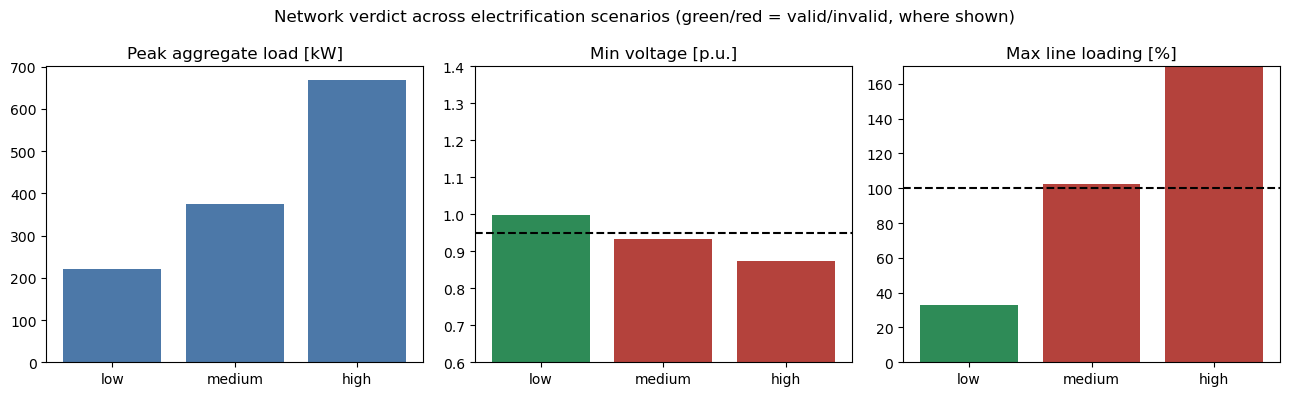

In [16]:
from digital_twin import run_digital_twin
from digital_twin.data_processing.process_data import process_data

# Only the keys process_data/run_digital_twin actually read at RUN time --
# NOT a spread of SCENARIO, which also carries generation-only keys
# (street_weights, mv_pv_installations, bss_bus, bss_park_e_kwh,
# bss_park_p_kw). run_digital_twin now RAISES if it sees the bss_* ones: a
# battery's bus/capacity/power is a fact of equipment.csv, never a runtime
# config scalar (see section 7).
verdicts = {}
for name, path in scenario_paths.items():
    run_config = {
        "data_path": path, "seed": SEED, "mois_simule": MOIS_SIMULE,
        "trafo_sn_mva": SCENARIO["trafo_sn_mva"],
    }
    (scenario_metadata, scenario_network, scenario_households,
     scenario_pv, scenario_bss, scenario_equipment) = process_data(run_config)
    out = run_digital_twin(run_config, scenario_metadata, scenario_network, scenario_households,
                           pv_profiles=scenario_pv, schedules_BSS=scenario_bss,
                           equipment=scenario_equipment)
    summary = out[out["category"] == "summary"].set_index("metric")["value"]
    verdicts[name] = {
        "network_valid": bool(summary["network_valid"]),
        "min_voltage_pu": float(summary["min_voltage_pu"]),
        "max_line_loading_pct": float(summary["max_line_loading_pct"]),
        "peak_agg_kw": float(summary["peak_agg_kw"]),
    }

verdicts = pd.DataFrame(verdicts).T
verdicts.index.name = "scenario"
display(verdicts)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, metric, title in zip(
    axes, ["peak_agg_kw", "min_voltage_pu", "max_line_loading_pct"],
    ["Peak aggregate load [kW]", "Min voltage [p.u.]", "Max line loading [%]"],
):
    colors = ["#2E8B57" if v else "#B4423C" for v in verdicts["network_valid"]] \
        if metric != "peak_agg_kw" else "#4C78A8"
    ax.bar(verdicts.index, verdicts[metric], color=colors)
    ax.set_title(title)

    if metric == "min_voltage_pu":
        ax.axhline(0.95, color="black", linestyle="--", label="0.95 p.u. limit")
        ax.set_ylim(0.6, 1.4)

    if metric == "max_line_loading_pct":
        ax.axhline(100.0, color="black", linestyle="--", label="100% limit")
        ax.set_ylim(0, 170)

fig.suptitle("Network verdict across electrification scenarios (green/red = valid/invalid, where shown)")
fig.tight_layout()
plt.show()

## Next step

Everything `main.py` needs is now under `out/processed/`:
`equipment.csv`, `metadata.csv`, `load_profiles.csv`, `mv_load_profiles.csv`,
`consumption_bank_real_weeks.parquet` and
`pvgis_irradiance_quarter_hourly.parquet` -- for the base scenario AND for
each of the three electrification scenarios built in section 9
(`data/bressoux/scenarios/{low,medium,high}/`). With `inputs/network.py` in
place, run the digital twin:

```bash
python main.py
```

`main.py` is set up to run the **Medium** electrification scenario as a worked
example (`data/bressoux/scenarios/medium`) -- change `config['data_path']`
there to point at `low`, `high`, or the base `data/bressoux` scenario instead.
See `docs/electrification_scenarios.md` for what each preset means.

`pv_profiles` and `schedules_BSS` are **not** files: they are rebuilt on every
call from `equipment.csv` + the irradiance + the loads, so a change of scenario
means editing the equipment table, not a pile of profile files. Every battery
-- the central one included -- is placed once, here, in `equipment.csv`:
`main.py`'s config never carries a battery's bus/capacity/power.

Keep `config['mois_simule']` in `main.py` equal to `MOIS_SIMULE` above. If they
differ, the run still works but the twin raises a `[LOAD/season]` warning: the
loads would come from one month and the sun from another.

Set `config['save'] = True` (the default) to write a Markdown report
(summary/violations/warnings) to `<data_path>/out/results/`.
